<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bubble Plots**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be directly loaded into pandas for analysis and visualization.

You will use various visualization techniques to explore the data and uncover key trends.


## Objectives


In this lab, you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two data features.

-   Visualize composition of data.

-   Visualize comparison of data.


#### Setup: Working with the Database
**Install and import the needed libraries**


In [1]:
!pip install pandas 
!pip install matplotlib

import pandas as pd
import matplotlib.pyplot as plt

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [2]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows of the data to understand its structure
df.head()

--2026-10-12 08:27:45--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  5.88MB/s    in 25s     

2026-10-12 08:28:11 (5.98 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondents’ age and their participation frequency (`SOPartFreq`) using a bubble plot.

- Use the size of the bubbles to represent their job satisfaction (`JobSat`).


SOPartFreq
Less than once per month or monthly                   12930
I have never participated in Q&A on Stack Overflow     4828
A few times per month or weekly                        3483
A few times per week                                   1310
Daily or almost daily                                   552
Multiple times per day                                  246
Name: count, dtype: int64
               Age                                         SOPartFreq  avg_jobsat    n  x  y
   18-24 years old                    A few times per month or weekly        6.89  330  1  2
   18-24 years old                               A few times per week        6.65  127  1  3
   18-24 years old                              Daily or almost daily        7.08   36  1  4
   18-24 years old I have never participated in Q&A on Stack Overflow        6.71  971  1  1
   18-24 years old                Less than once per month or monthly        6.74 1484  1  0
   25-34 years old                    A few t

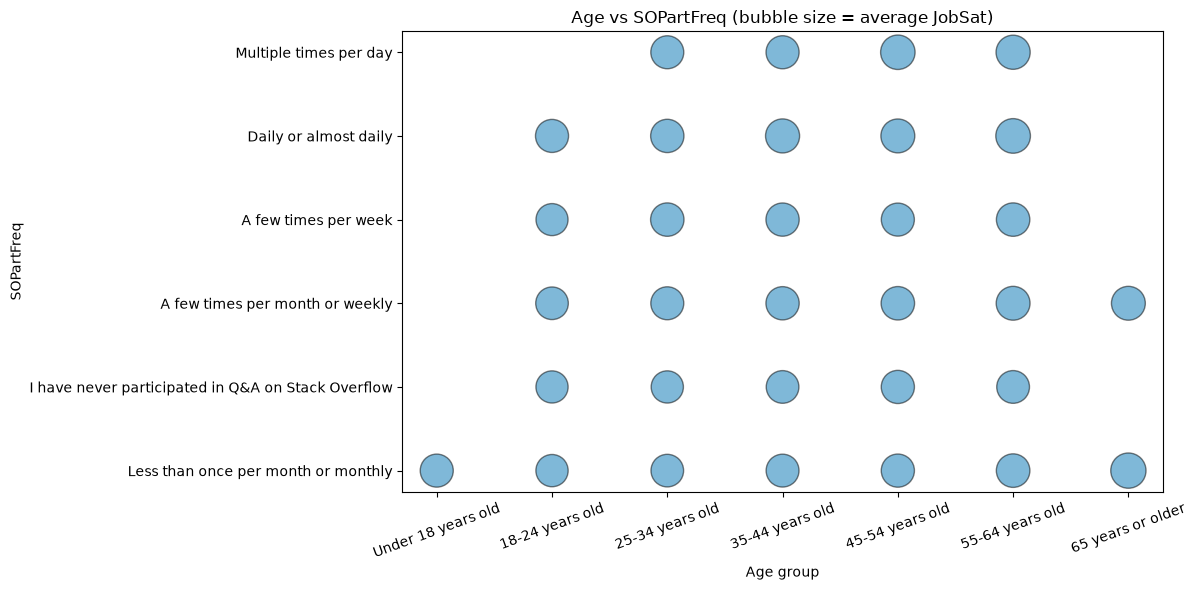

In [3]:
##Write your code here
##Write your code here
import numpy as np

d = df[["Age", "SOPartFreq", "JobSat"]].copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna()
d = d[d["Age"] != "Prefer not to say"]
print(d["SOPartFreq"].value_counts())

age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]
freq_order = d["SOPartFreq"].value_counts().index.tolist()    # most common first

g = d.groupby(["Age", "SOPartFreq"]).agg(avg_jobsat=("JobSat", "mean"), n=("JobSat", "size")).reset_index()
g = g[g["n"] >= 20]
g["x"] = g["Age"].map({a: i for i, a in enumerate(age_order)})
g["y"] = g["SOPartFreq"].map({f: i for i, f in enumerate(freq_order)})
print(g.round(2).sort_values(["Age", "SOPartFreq"]).to_string(index=False))

plt.figure(figsize=(12, 6))
plt.scatter(g["x"], g["y"], s=g["avg_jobsat"] * 80, alpha=0.5, color="#0072B2", edgecolor="black")
plt.xticks(range(len(age_order)), age_order, rotation=20)
plt.yticks(range(len(freq_order)), freq_order)
plt.title("Age vs SOPartFreq (bubble size = average JobSat)")
plt.xlabel("Age group")
plt.ylabel("SOPartFreq")
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Compensation vs. Job Satisfaction


-Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).

- Use the size of the bubbles to represent respondents’ age.


Rows available: 15264

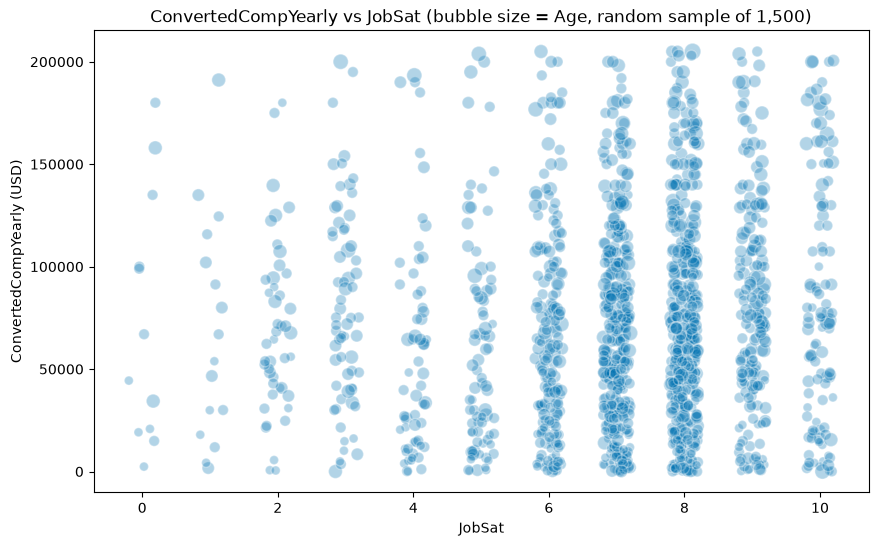

In [4]:
##Write your code here
age_map = {
    "Under 18 years old": 16, "18-24 years old": 21, "25-34 years old": 29.5, "35-44 years old": 39.5,
    "45-54 years old": 49.5, "55-64 years old": 59.5, "65 years or older": 70,
}

d2 = df[["ConvertedCompYearly", "JobSat", "Age"]].copy()
d2["JobSat"] = pd.to_numeric(d2["JobSat"], errors="coerce")
d2["Age_numeric"] = d2["Age"].map(age_map)
d2 = d2.dropna()
d2 = d2[d2["ConvertedCompYearly"] <= d2["ConvertedCompYearly"].quantile(0.95)]
print("Rows available:", len(d2))

sample = d2.sample(1500, random_state=1)
rng = np.random.default_rng(0)
plt.figure(figsize=(10, 6))
plt.scatter(sample["JobSat"] + rng.uniform(-0.2, 0.2, len(sample)), sample["ConvertedCompYearly"],
            s=sample["Age_numeric"] * 2, alpha=0.3, color="#0072B2", edgecolor="white")
plt.title("ConvertedCompYearly vs JobSat (bubble size = Age, random sample of 1,500)")
plt.xlabel("JobSat")
plt.ylabel("ConvertedCompYearly (USD)")
plt.show()

### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.

- Use bubble size to represent the frequency of each language.



Age                      Under 18 years old  18-24 years old  25-34 years old  \
Language                                                                        
JavaScript                             1538             8518            13691   
HTML/CSS                               1560             7724            11253   
SQL                                     656             6257            11037   
Python                                 1656             7868            10927   
TypeScript                              718             5128             9459   
Bash/Shell (all shells)                 746             4069             7277   
Java                                    817             5038             6190   
C#                                      650             3442             5430   
C++                                     902             4543             4047   
C                                       746             4309             3307   

Age                      35

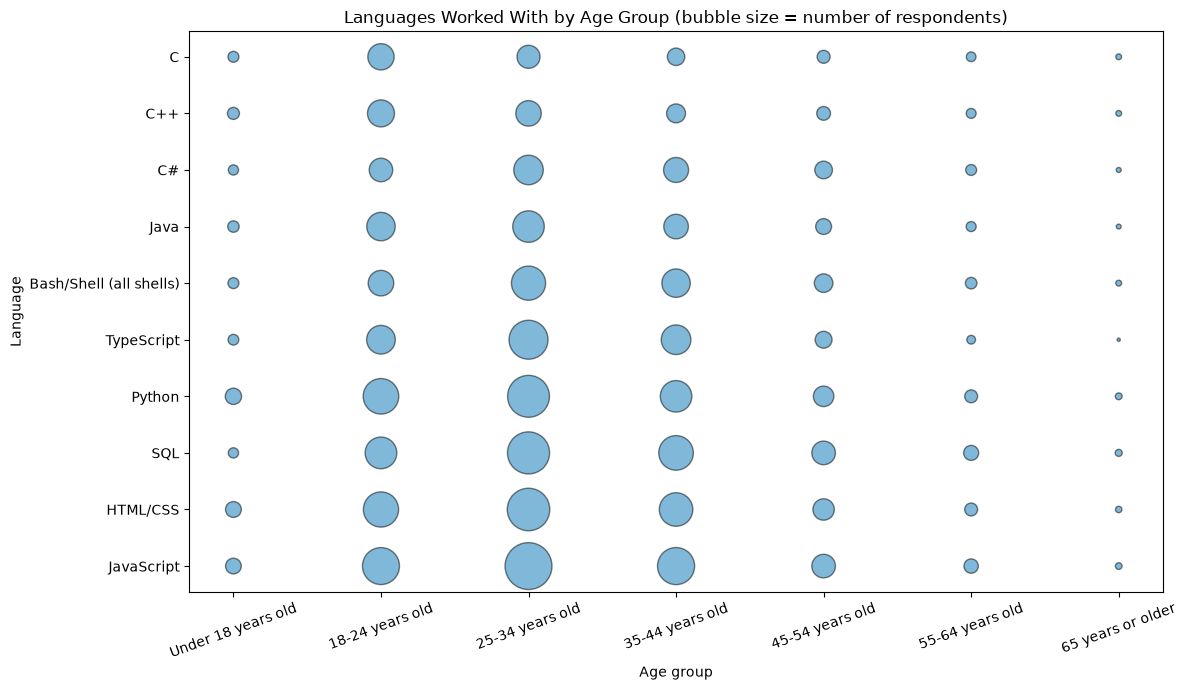

In [5]:
##Write your code here
import numpy as np

age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "LanguageHaveWorkedWith"]].dropna().copy()
d = d[d["Age"].isin(age_order)]
d["Language"] = d["LanguageHaveWorkedWith"].str.split(";")
d = d.explode("Language")
d["Language"] = d["Language"].str.strip()

top_lang = d["Language"].value_counts().head(10).index.tolist()
g = d[d["Language"].isin(top_lang)].groupby(["Age", "Language"]).size().reset_index(name="count")
print(g.pivot(index="Language", columns="Age", values="count").reindex(index=top_lang, columns=age_order))

g["x"] = g["Age"].map({a: i for i, a in enumerate(age_order)})
g["y"] = g["Language"].map({l: i for i, l in enumerate(top_lang)})

plt.figure(figsize=(12, 7))
plt.scatter(g["x"], g["y"], s=g["count"] / 12, alpha=0.5, color="#0072B2", edgecolor="black")
plt.xticks(range(len(age_order)), age_order, rotation=20)
plt.yticks(range(len(top_lang)), top_lang)
plt.title("Languages Worked With by Age Group (bubble size = number of respondents)")
plt.xlabel("Age group")
plt.ylabel("Language")
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.

- Use bubble size to indicate the number of respondents for each database.


                      respondents  avg_jobsat
Database                                     
PostgreSQL                  13261        6.94
SQLite                       6859        6.92
Redis                        6436        6.98
MySQL                        5973        6.98
MongoDB                      5655        6.90
Microsoft SQL Server         4615        7.07
Elasticsearch                3873        7.00
MariaDB                      3101        6.99
Dynamodb                     2150        7.08
BigQuery                     1423        6.95

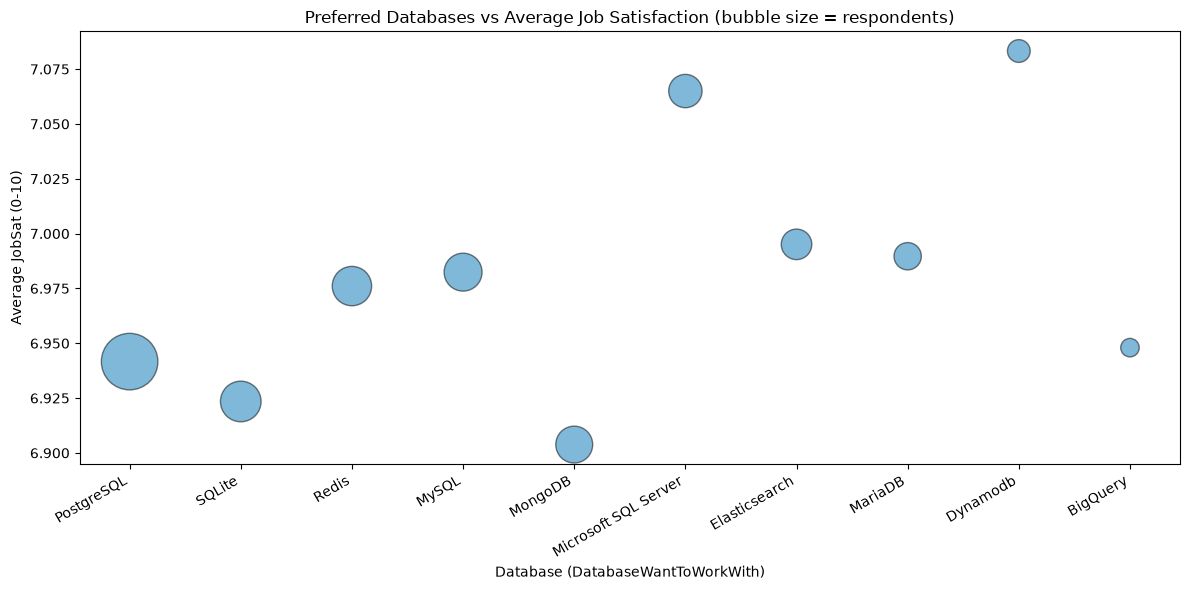

In [7]:
##Write your code here
d = df[["DatabaseWantToWorkWith", "JobSat"]].copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna()
d["Database"] = d["DatabaseWantToWorkWith"].str.split(";")
d = d.explode("Database")
d["Database"] = d["Database"].str.strip()

db = d.groupby("Database").agg(respondents=("JobSat", "size"), avg_jobsat=("JobSat", "mean"))
top = db.sort_values("respondents", ascending=False).head(10)
print(top.round(2))

plt.figure(figsize=(12, 6))
plt.scatter(range(len(top)), top["avg_jobsat"], s=top["respondents"] / 8, alpha=0.5,
            color="#0072B2", edgecolor="black")
plt.xticks(range(len(top)), top.index, rotation=30, ha="right")
plt.title("Preferred Databases vs Average Job Satisfaction (bubble size = respondents)")
plt.xlabel("Database (DatabaseWantToWorkWith)")
plt.ylabel("Average JobSat (0-10)")
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles

- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).

- Use bubble size to represent job satisfaction.


                                               respondents  median_comp  \
Role                                                                      
Developer, full-stack                                 5792      62846.5   
Developer, back-end                                   3419      68677.0   
Developer, front-end                                   924      50482.0   
Developer, desktop or enterprise applications          705      61062.0   
Developer, mobile                                      573      54467.0   
Developer, embedded applications or devices            511      69814.0   
Other (please specify):                                420      83824.0   
Engineering manager                                    416     113055.5   
Data engineer                                          394      73218.5   
DevOps specialist                                      334      69552.0   

                                               avg_jobsat  
Role                                   

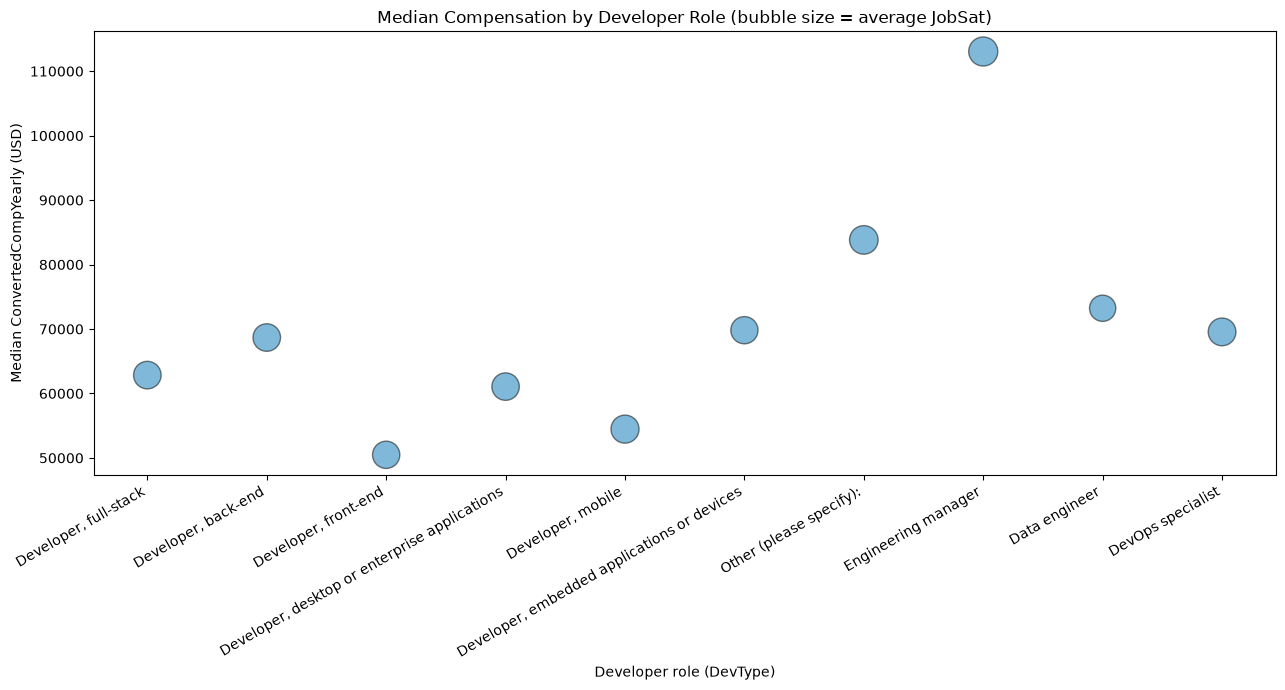

In [8]:
##Write your code here
d = df[["DevType", "ConvertedCompYearly", "JobSat"]].copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna()
d["Role"] = d["DevType"].str.split(";")
d = d.explode("Role")
d["Role"] = d["Role"].str.strip()

roles = d.groupby("Role").agg(respondents=("JobSat", "size"),
                              median_comp=("ConvertedCompYearly", "median"),
                              avg_jobsat=("JobSat", "mean"))
top = roles.sort_values("respondents", ascending=False).head(10)
print(top.round(2))

plt.figure(figsize=(13, 7))
plt.scatter(range(len(top)), top["median_comp"], s=top["avg_jobsat"] ** 3 * 1.2,
            alpha=0.5, color="#0072B2", edgecolor="black")
plt.xticks(range(len(top)), top.index, rotation=30, ha="right")
plt.title("Median Compensation by Developer Role (bubble size = average JobSat)")
plt.xlabel("Developer role (DevType)")
plt.ylabel("Median ConvertedCompYearly (USD)")
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Collaboration Tools by Age

- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.

- Use bubble size to represent the frequency of tool usage.


Age                          Under 18 years old  18-24 years old  \
Tool                                                               
Visual Studio Code                         1808             9598   
Visual Studio                               780             3838   
IntelliJ IDEA                               622             3932   
Notepad++                                   412             2368   
Vim                                         438             2471   
Android Studio                              479             2663   
PyCharm                                     473             2476   
Jupyter Notebook/JupyterLab                 191             2122   
Neovim                                      522             2289   
Sublime Text                                235             1209   

Age                          25-34 years old  35-44 years old  \
Tool                                                            
Visual Studio Code                     16064         

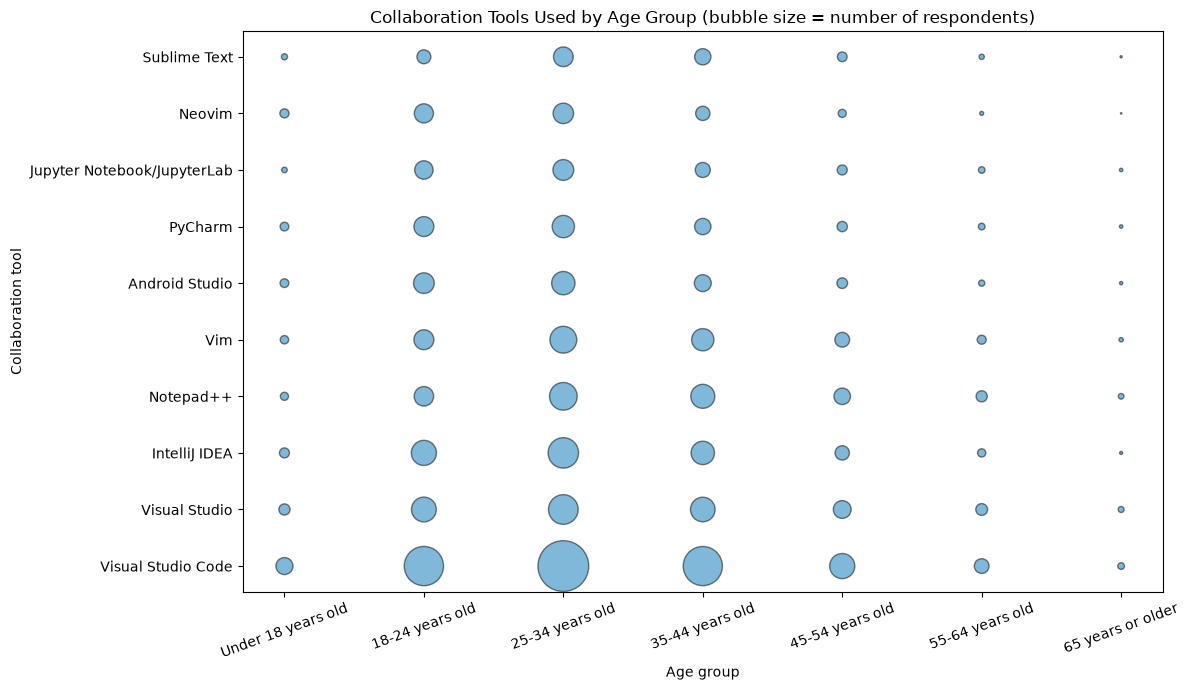

In [9]:
##Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

d = df[["Age", "NEWCollabToolsHaveWorkedWith"]].dropna().copy()
d = d[d["Age"].isin(age_order)]
d["Tool"] = d["NEWCollabToolsHaveWorkedWith"].str.split(";")
d = d.explode("Tool")
d["Tool"] = d["Tool"].str.strip()

top_tools = d["Tool"].value_counts().head(10).index.tolist()
g = d[d["Tool"].isin(top_tools)].groupby(["Age", "Tool"]).size().reset_index(name="count")
print(g.pivot(index="Tool", columns="Age", values="count").reindex(index=top_tools, columns=age_order))

g["x"] = g["Age"].map({a: i for i, a in enumerate(age_order)})
g["y"] = g["Tool"].map({t: i for i, t in enumerate(top_tools)})

plt.figure(figsize=(12, 7))
plt.scatter(g["x"], g["y"], s=g["count"] / 12, alpha=0.5, color="#0072B2", edgecolor="black")
plt.xticks(range(len(age_order)), age_order, rotation=20)
plt.yticks(range(len(top_tools)), top_tools)
plt.title("Collaboration Tools Used by Age Group (bubble size = number of respondents)")
plt.xlabel("Age group")
plt.ylabel("Collaboration tool")
plt.tight_layout()
plt.show()

### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction

- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.

- Use bubble size to represent the number of respondents.



              respondents  avg_jobsat
Framework                            
React                8167        6.95
Node.js              7636        7.01
Next.js              4322        6.91
ASP.NET CORE         4199        7.05
Vue.js               4061        6.92
Angular              3541        7.01
Spring Boot          2940        6.89
Express              2855        6.88
FastAPI              2731        6.82
Svelte               2710        6.79

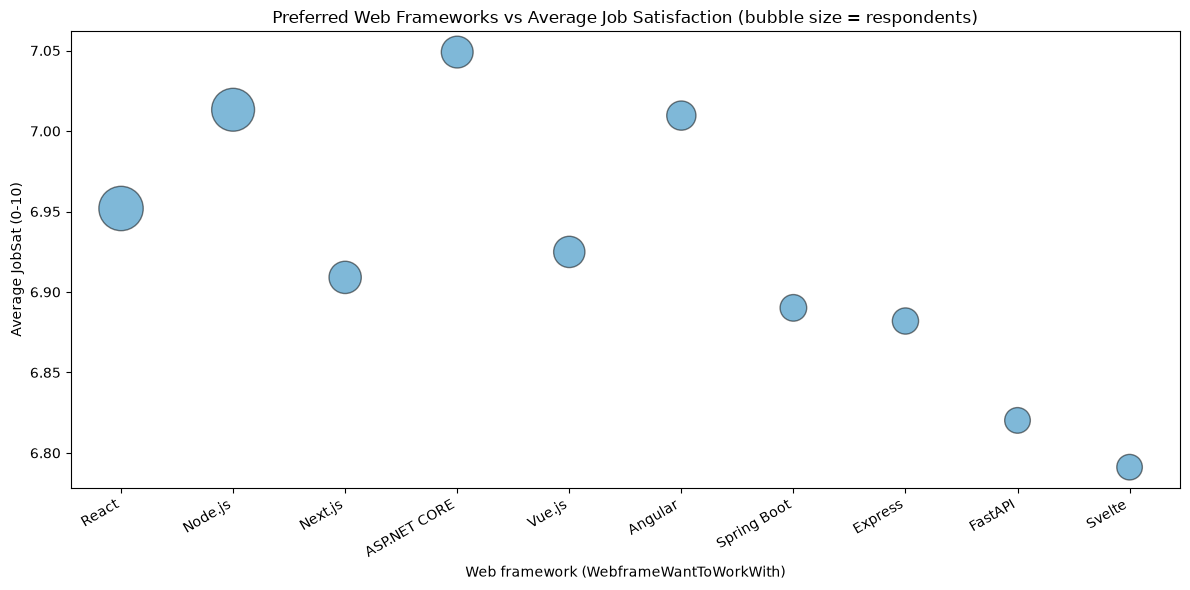

In [10]:
##Write your code here
d = df[["WebframeWantToWorkWith", "JobSat"]].copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna()
d["Framework"] = d["WebframeWantToWorkWith"].str.split(";")
d = d.explode("Framework")
d["Framework"] = d["Framework"].str.strip()

fw = d.groupby("Framework").agg(respondents=("JobSat", "size"), avg_jobsat=("JobSat", "mean"))
top = fw.sort_values("respondents", ascending=False).head(10)
print(top.round(2))

plt.figure(figsize=(12, 6))
plt.scatter(range(len(top)), top["avg_jobsat"], s=top["respondents"] / 8, alpha=0.5,
            color="#0072B2", edgecolor="black")
plt.xticks(range(len(top)), top.index, rotation=30, ha="right")
plt.title("Preferred Web Frameworks vs Average Job Satisfaction (bubble size = respondents)")
plt.xlabel("Web framework (WebframeWantToWorkWith)")
plt.ylabel("Average JobSat (0-10)")
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Admired Technologies Across Countries

- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).

- Use bubble size to represent the frequency of admiration.



Country                  United States of America  Germany  India  \
Language                                                            
Python                                       4190     1861   1424   
JavaScript                                   3728     1600   1722   
SQL                                          3765     1608   1303   
HTML/CSS                                     3513     1710   1310   
TypeScript                                   2767     1355    960   
Bash/Shell (all shells)                      2872     1334    478   
C#                                           2057      759    357   
Java                                         1280      952    801   
C++                                          1470      757    522   
Rust                                         1357      727    232   

Country                  United Kingdom of Great Britain and Northern Ireland  \
Language                                                                        
Python   

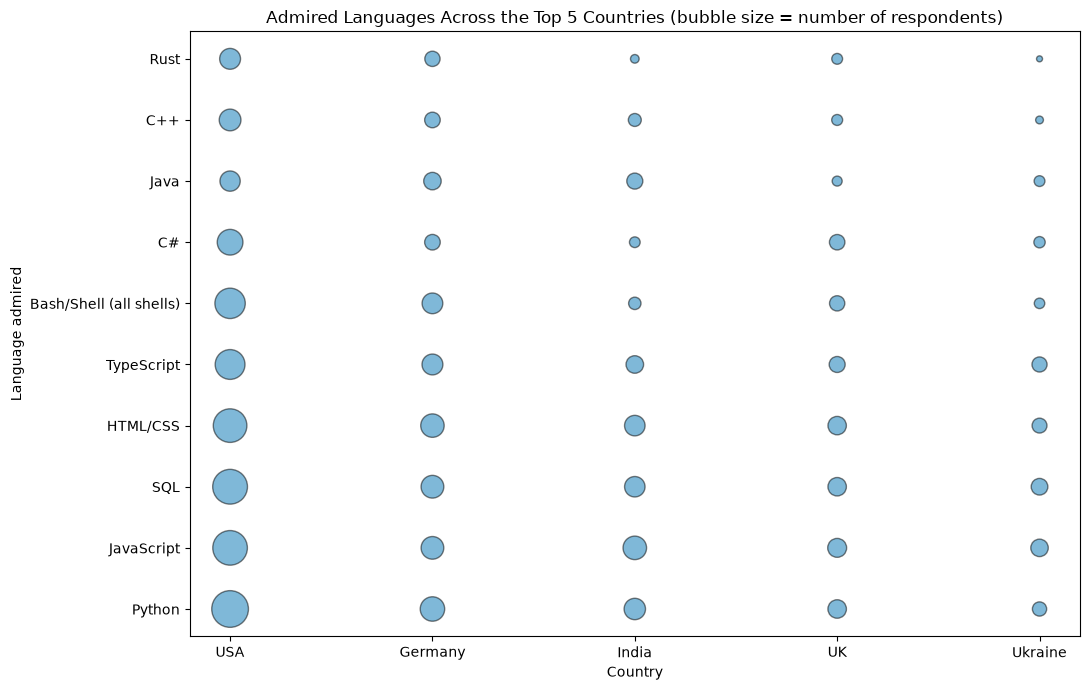

In [11]:
##Write your code here
d = df[["Country", "LanguageAdmired"]].dropna().copy()
top_countries = d["Country"].value_counts().head(5).index.tolist()
d = d[d["Country"].isin(top_countries)]
d["Language"] = d["LanguageAdmired"].str.split(";")
d = d.explode("Language")
d["Language"] = d["Language"].str.strip()

top_lang = d["Language"].value_counts().head(10).index.tolist()
g = d[d["Language"].isin(top_lang)].groupby(["Country", "Language"]).size().reset_index(name="count")
print(g.pivot(index="Language", columns="Country", values="count").reindex(index=top_lang, columns=top_countries))

short = {"United States of America": "USA", "United Kingdom of Great Britain and Northern Ireland": "UK"}
g["x"] = g["Country"].map({c: i for i, c in enumerate(top_countries)})
g["y"] = g["Language"].map({l: i for i, l in enumerate(top_lang)})

plt.figure(figsize=(11, 7))
plt.scatter(g["x"], g["y"], s=g["count"] / 6, alpha=0.5, color="#0072B2", edgecolor="black")
plt.xticks(range(len(top_countries)), [short.get(c, c) for c in top_countries])
plt.yticks(range(len(top_lang)), top_lang)
plt.title("Admired Languages Across the Top 5 Countries (bubble size = number of respondents)")
plt.xlabel("Country")
plt.ylabel("Language admired")
plt.tight_layout()
plt.show()

## Final Step: Review


After completing the lab, you will have extensively used bubble plots to gain insights into developer community preferences, demographics, compensation trends, and job satisfaction.


## Summary


After completing this lab, you will be able to:

- Create and interpret bubble plots to analyze relationships and compositions within datasets.

- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.

- Apply bubble plots to visualize complex relationships involving multiple dimensions effectively.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
